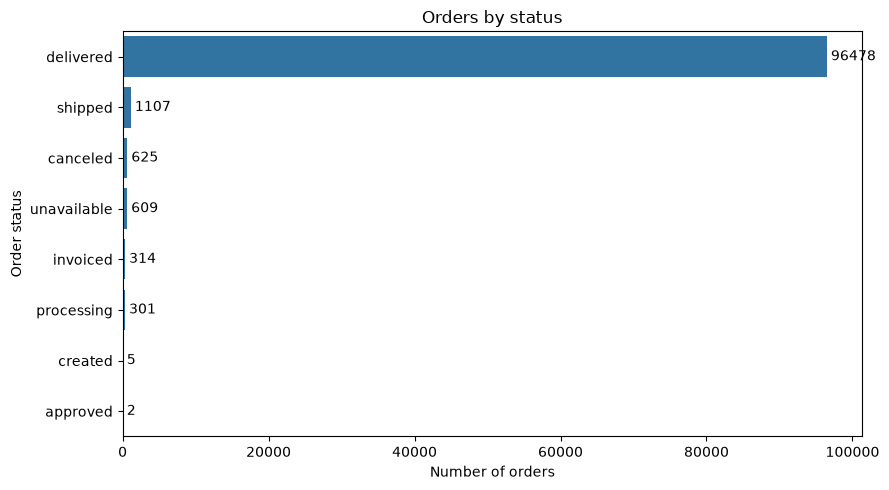

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

import pandas as pd
from sqlalchemy import create_engine

engine = create_engine("postgresql+psycopg2://a111@localhost:5432/olist")

dt = pd.read_sql("SELECT order_status, COUNT(*) AS cnt FROM orders GROUP BY 1 ORDER BY 2 DESC", engine)

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=dt, x="cnt", y="order_status")
ax.bar_label(ax.containers[0], fmt="%d", padding=3) 

plt.title("Orders by status")
plt.xlabel("Number of orders")
plt.ylabel("Order status")
plt.tight_layout()
plt.show()

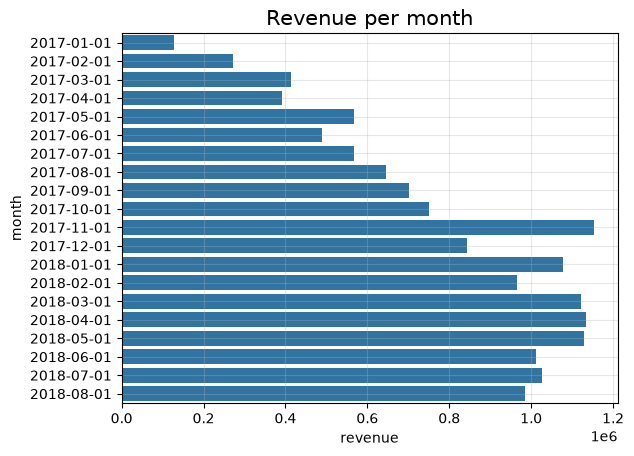

In [2]:
dt = pd.read_sql("select date_trunc('month', o.order_purchase_timestamp)::date as month, sum(p.payment_value) as revenue from orders_period o join order_payments p on o.order_id = p.order_id inner join orders_delivered d on o.order_id = d.order_id group by month order by month", engine)
sns.barplot(data=dt, x='revenue', y='month',)
plt.title('Revenue per month', fontsize=15,)
plt.grid(alpha=0.3)

### 📊 Ключевые выводы по графику выручки:

* **Стабильный рост в 2017 году:** Бизнес рос с каждым месяцем. Яркий пик виден в **ноябре 2017 года** — скорее всего, это результат распродаж в «Черную пятницу».
* **Пик и плато весной 2018:** Март, апрель и май стали самыми успешными месяцами за весь период. Выручка стабильно держалась на максимальном уровне (выше 1.1 млн).
* **Летний спад 2018:** Начиная с июня, продажи начинают плавно снижаться и падают ниже 1 млн. 

**Что делать дальше (Гипотеза):** 
Нужно проверить, почему падает выручка летом 2018. Причиной может быть либо сезонное падение **среднего чека**, либо рост **отмен заказов** на этапе доставки.


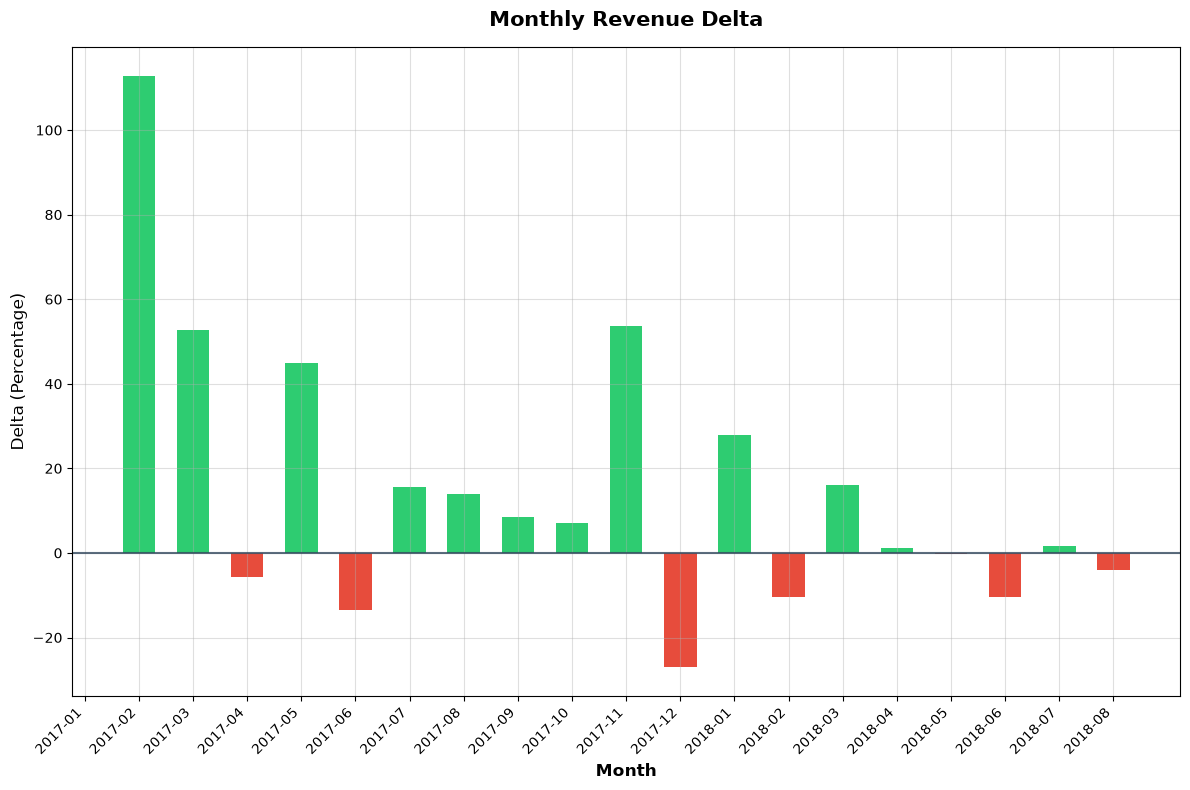

In [3]:
dt = pd.read_sql("with monthly_revenue as (select date_trunc('month', o.order_purchase_timestamp)::date as month, sum(p.payment_value) as revenue from orders_period o join order_payments p on o.order_id = p.order_id inner join orders_delivered d on o.order_id = d.order_id group by month order by month) select month, revenue, (revenue - lag(revenue) over(order by month)) / (lag(revenue) over(order by month)) * 100 as revenue_diff from monthly_revenue", engine)
colors = ['#2ecc71' if x >= 0 else '#e74c3c' for x in dt['revenue_diff']]
dt['month'] = pd.to_datetime(dt['month'])
plt.figure(figsize=(12, 8))
plt.xlabel('Months', fontsize=15, fontweight='bold')
bars = plt.bar(
    dt['month'].dt.strftime('%Y-%m'), 
    dt['revenue_diff'],
    color=colors,
    edgecolor='none',
    width=0.6
)
plt.grid(alpha=0.4)
plt.axhline(0, color='#34495e', linestyle='-', linewidth=1.5, alpha=0.8)
plt.title('Monthly Revenue Delta', fontsize=15, weight='bold', pad=15)
plt.ylabel('Delta (Percentage)', fontsize=12, rotation=90)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Month', fontsize=12)
plt.tight_layout()
plt.show()

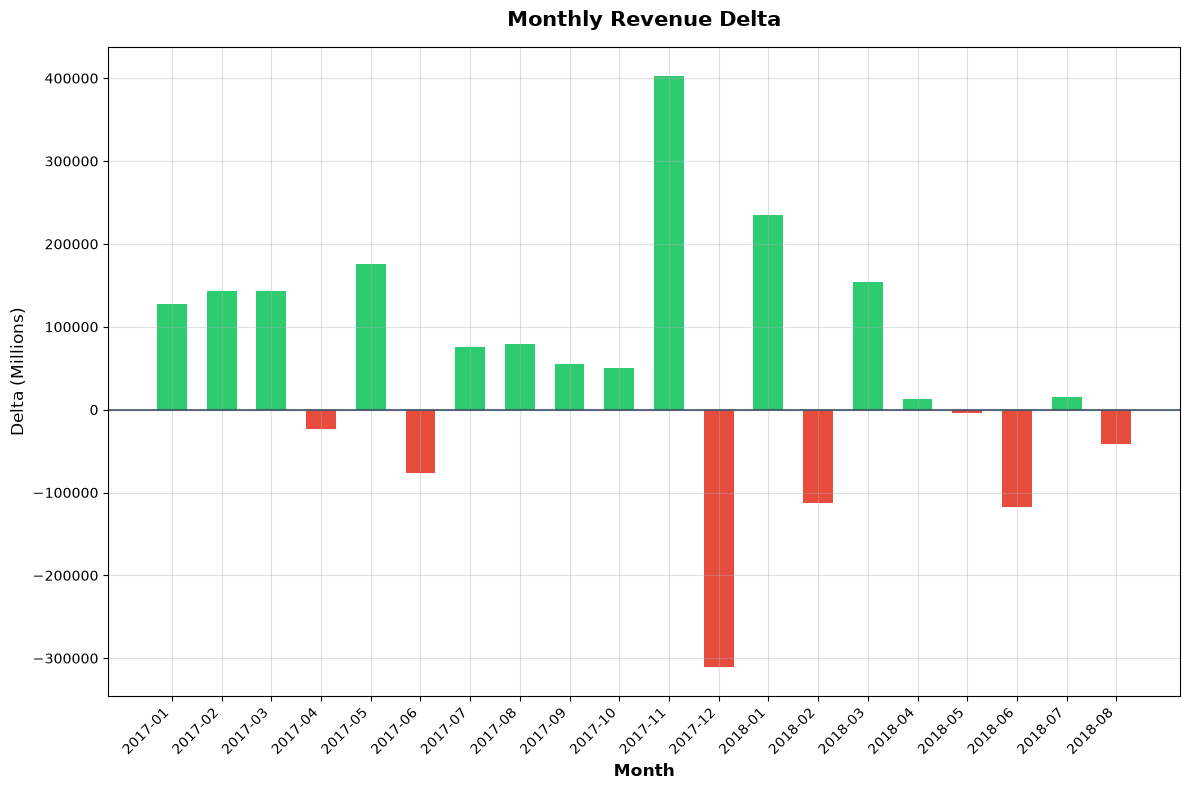

In [4]:
dt = pd.read_sql("with monthly_revenue as (select date_trunc('month', o.order_purchase_timestamp)::date as month, sum(p.payment_value) as revenue from orders_period o join order_payments p on o.order_id = p.order_id inner join orders_delivered d on o.order_id = d.order_id group by month order by month) select month, revenue, (revenue - lag(revenue, 1, 0) over(order by month)) as revenue_diff from monthly_revenue", engine)
colors = ['#2ecc71' if x >= 0 else '#e74c3c' for x in dt['revenue_diff']]
dt['month'] = pd.to_datetime(dt['month'])
plt.figure(figsize=(12, 8))
plt.xlabel('Months', fontsize=15, fontweight='bold')
bars = plt.bar(
    dt['month'].dt.strftime('%Y-%m'), 
    dt['revenue_diff'],
    color=colors,
    edgecolor='none',
    width=0.6
)
plt.grid(alpha=0.4)
plt.axhline(0, color='#34495e', linestyle='-', linewidth=1.5, alpha=0.8)
plt.title('Monthly Revenue Delta', fontsize=15, weight='bold', pad=15)
plt.ylabel('Delta (Millions)', fontsize=12, rotation=90)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Month', fontsize=12)
plt.tight_layout()
plt.show()

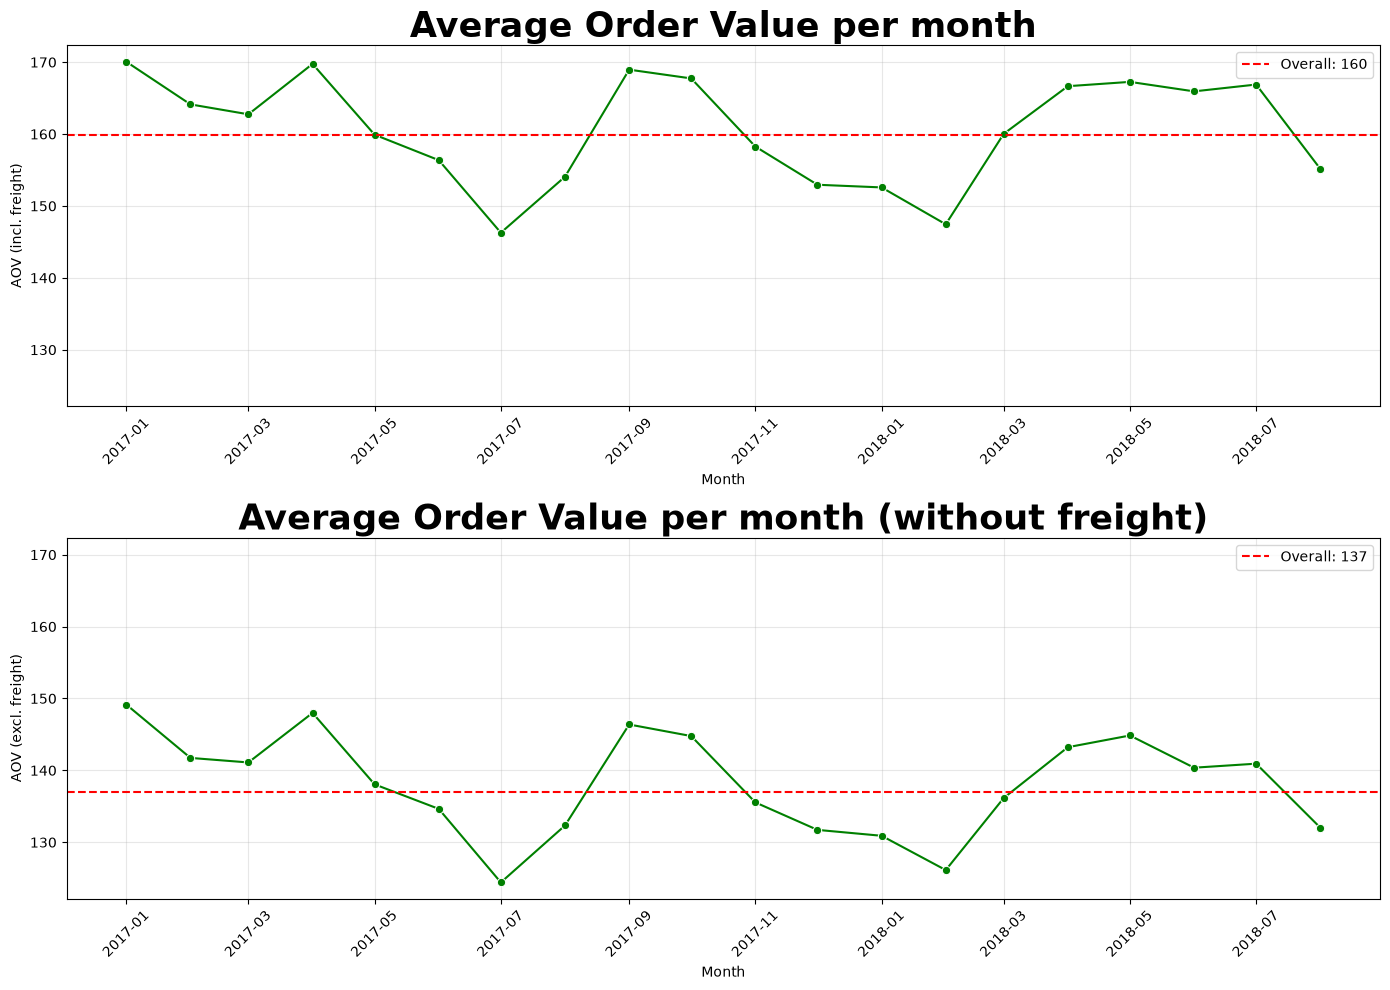

In [5]:
BASE = """
    WITH pay AS (
        SELECT order_id, SUM(payment_value) AS paid
        FROM order_payments
        GROUP BY order_id
    ),
    items AS (
        SELECT order_id, SUM(freight_value) AS freight
        FROM order_items
        GROUP BY order_id
    ),
    orders_base AS (
        SELECT d.order_id,
               DATE_TRUNC('month', d.order_purchase_timestamp)::date AS month,
               COALESCE(pay.paid, 0)      AS paid,
               COALESCE(items.freight, 0) AS freight
        FROM orders_delivered d
        LEFT JOIN pay   ON pay.order_id   = d.order_id
        LEFT JOIN items ON items.order_id = d.order_id
    )
"""

monthly = pd.read_sql(BASE + """
    SELECT month,
           ROUND(AVG(paid), 2)::float           AS aov,
           ROUND(AVG(paid - freight), 2)::float AS aov_ex_freight
    FROM orders_base
    GROUP BY month
    ORDER BY month
""", engine)

overall = pd.read_sql(BASE + """
    SELECT ROUND(AVG(paid), 2)::float           AS aov,
           ROUND(AVG(paid - freight), 2)::float AS aov_ex_freight
    FROM orders_base
""", engine).iloc[0]

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharey=True)

panels = [
    ("aov",            "AOV (incl. freight)",  "Average Order Value per month"),
    ("aov_ex_freight", "AOV (excl. freight)",  "Average Order Value per month (without freight)"),
]

for ax, (col, ylabel, title) in zip(axes, panels):
    sns.lineplot(data=monthly, x="month", y=col, marker="o", color="green", ax=ax)
    ax.axhline(overall[col], color="red", linestyle="--",
               label=f"Overall: {overall[col]:.0f}")
    ax.set_title(title, fontsize=25, weight='bold')
    ax.set_xlabel("Month")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

### Средний чек (AOV) по месяцам

**Метрика:** AOV = сумма платежей (с учетом доставки) / число уникальных заказов. Считается по доставленным заказам за период янв 2017 – авг 2018.

**Общий AOV за период: ~160 $.**

**Наблюдения:**
- Средний чек колеблется в диапазоне **~146–170 R$**, то есть около ±8% от общего значения. Резких скачков нет, показатель стабилен.
- На графике заметна волнообразная динамика с периодом около полугода. 
- Это может указывать на сезонность, но данных недостаточно для вывода: в выборке всего 20 месяцев. 

In [6]:
top_c = pd.read_sql('with cat as (select pc.category_en as category, count(*) as items_sold, COUNT(DISTINCT i.order_id)  as cnt_orders, avg(i.price) as avg_price, sum(i.price) as revenue from orders_delivered d join order_items i on d.order_id = i.order_id join products_clean pc on pc.product_id = i.product_id group by pc.category_en order by revenue desc) select category, items_sold, cnt_orders, round(avg_price, 2) as avg_price, revenue, round(100 * revenue / sum(revenue) over(), 2) as revenue_pct, round(100 * sum(revenue) over (order by revenue desc) / sum(revenue) over (), 2) as cumulative_pct from cat', engine)
top_c

,category,items_sold,cnt_orders,avg_price,revenue,revenue_pct,cumulative_pct
0,health_beauty,9422,8610,130.50,1229557.50,9.33,9.33
1,watches_gifts,5853,5489,198.73,1163187.91,8.83,18.15
2,bed_bath_table,10945,9267,93.46,1022955.77,7.76,25.92
3,sports_leisure,8413,7512,113.24,952661.40,7.23,33.14
4,computers_accessories,7631,6517,116.36,887944.60,6.74,39.88
...,...,...,...,...,...,...,...
69,flowers,33,29,33.64,1110.04,0.01,99.98
70,home_comfort_2,30,24,25.34,760.27,0.01,99.99
71,cds_dvds_musicals,14,12,52.14,730.00,0.01,99.99
72,fashion_childrens_clothes,7,7,74.28,519.95,0.00,100.00


Text(0.5, 1.0, 'Revenue share of top 10 categories')

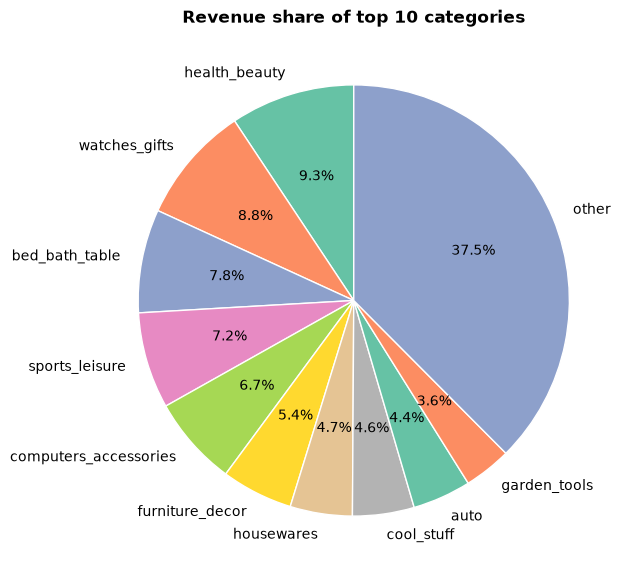

In [7]:
plt.figure(figsize=(7, 7))
top10_c = top_c.head(10).copy()
other = pd.DataFrame({"category": ['other'], 'revenue': [top_c['revenue'].iloc[10:].sum()]})
top = pd.concat([top10_c[['category', 'revenue']], other], ignore_index=True)
plt.pie(
    top["revenue"],
    labels=top["category"],
    autopct="%1.1f%%",          
    startangle=90,  
    colors = sns.color_palette("Set2", len(top)),          
    wedgeprops={"edgecolor": "white"},
)
plt.title("Revenue share of top 10 categories", weight='bold')


### Топ-10 категорий по выручке

**Метрика:** выручка = сумма цен товаров (`price`, без доставки) по доставленным заказам за период янв 2017 – авг 2018. Платежи по категориям не разделить, потому что платёж относится к заказу целиком, а в заказе могут быть товары из разных категорий.

**Выводы:**
- Выручка распределена достаточно равномерно: нет категории, которая занимала бы больше 10%. Лидеры: `health_beauty` (9,3%), `watches_gifts` (8,8%) и `bed_bath_table` (7,8%).
- Топ-3 категории дают около 26% выручки, топ-10 дают 62,5%. Остальные 37,5% приходятся на категории вне топ-10 (всего их около 70).
- Выручка диверсифицирована по категориям: она не держится на одной-двух, а распределена между многими. Самая крупная категория даёт 9,3%, и даже топ-3 вместе дают около 26%. Поэтому падение спроса в одной категории не обрушит выручку, зависимость от любой из них невысокая.

**Ограничения:** доля товаров без категории (`unknown`) ~ 1,29% и точное число категорий в хвосте 64. Доля в выручке не равна доле в заказах: категория с дорогими товарами может занимать высокое место по деньгам, но продаваться редко.

### Объём продаж и цена по категориям

Выручка категории равна числу проданных позиций, умноженному на среднюю цену. Посмотрим на обе составляющие вместе, чтобы понять, какие категории зарабатывают за счёт объёма, а какие за счёт цены.

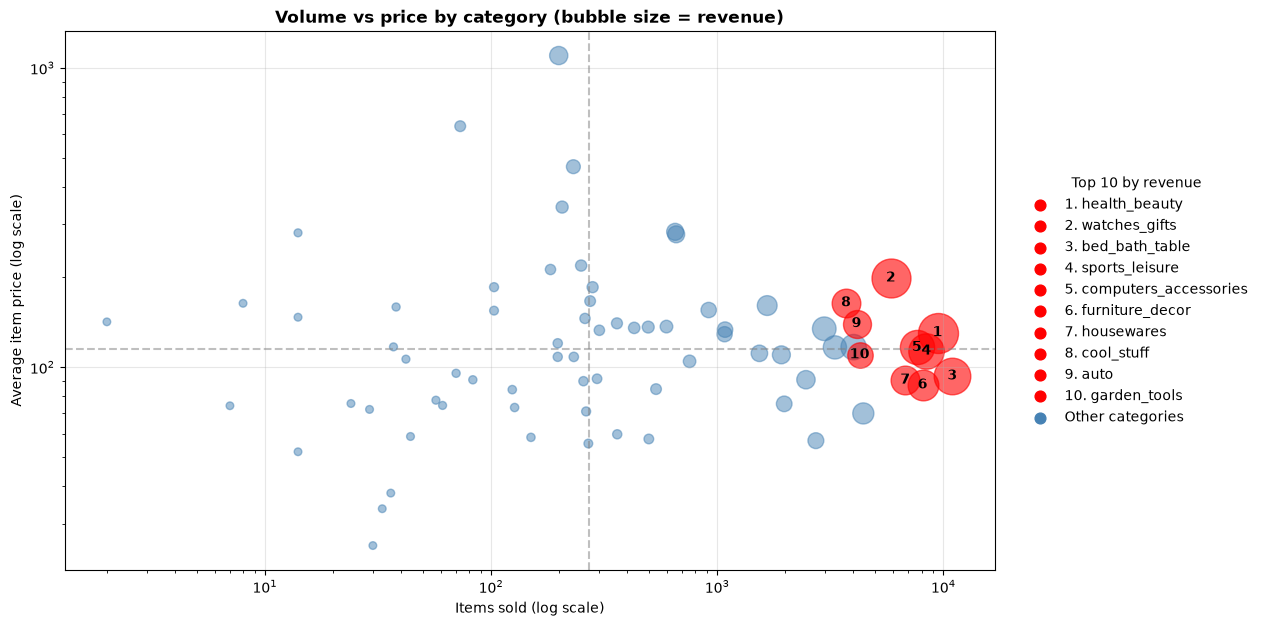

In [19]:
# 1. Подготовка данных
df = top_c.copy()
for col in ["revenue", "items_sold", "avg_price"]:
    df[col] = df[col].astype(float)

df = df.sort_values("revenue", ascending=False)          
df["size"] = df["revenue"] / df["revenue"].max() * 800 + 30   

top10 = df.head(10)       
others = df.iloc[10:]    

x_med = df["items_sold"].median()
y_med = df["avg_price"].median()

plt.figure(figsize=(12, 7))

plt.scatter(others["items_sold"], others["avg_price"],
            s=others["size"], color="steelblue", alpha=0.5)

for i, (cat, x, y, size) in enumerate(
        zip(top10["category"], top10["items_sold"], top10["avg_price"], top10["size"]), start=1):
    plt.scatter(x, y, s=size, color="red", alpha=0.6)                       
    plt.text(x, y, str(i), ha="center", va="center", color="black", fontweight="bold")
    plt.scatter([], [], s=60, color="red", label=f"{i}. {cat}")             # строка в легенде

plt.scatter([], [], s=60, color="steelblue", label="Other categories")      # строка в легенде

# линии медиан
plt.axvline(x_med, color="gray", linestyle="--", alpha=0.5)   
plt.axhline(y_med, color="gray", linestyle="--", alpha=0.5) 

# оформление
plt.xscale("log")
plt.yscale("log")
plt.title("Volume vs price by category (bubble size = revenue)", weight="bold")
plt.xlabel("Items sold (log scale)")
plt.ylabel("Average item price (log scale)")
plt.grid(alpha=0.3)
plt.legend(title="Top 10 by revenue", loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
plt.show()

### Объём продаж и цена по категориям

**Как читать график:** каждая точка это категория, размер точки показывает выручку. Красные точки с номерами это топ-10 по выручке, синие остальные категории. Пунктирные линии проходят по медианам. Обе оси логарифмические, потому что значения различаются в десятки раз.

**Выводы:**
- Все категории из топ-10 расположены в правой части графика: по числу проданных позиций они заметно опережают остальные категории. Это главная причина их высокой выручки.
- По цене топ-10 неоднороден. Часть категорий продаёт товары дороже медианы (например, `watches_gifts`), а часть дешевле медианы: `bed_bath_table`, `housewares`, `furniture_decor`.
- Значит, выручку лидеров обеспечивает прежде всего объём, а не высокая цена. Категории с низкой ценой позиции зарабатывают за счёт большого числа продаж, категории с высокой ценой получают дополнительный вклад от стоимости товаров.
- Для бизнеса это значит, что рост выручки в основном зависит от числа заказов, поэтому важнее привлекать покупателей и удерживать спрос, чем поднимать цены.